In [66]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [67]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

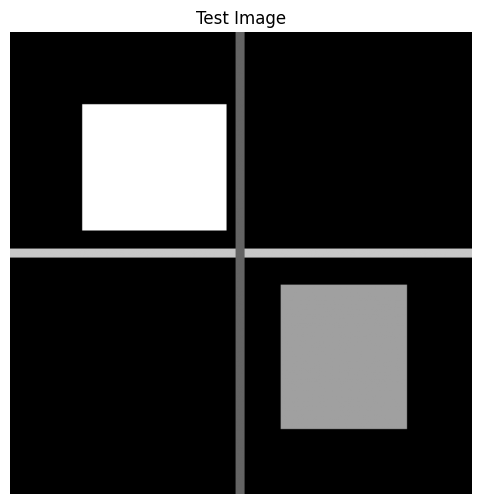

In [68]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [69]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


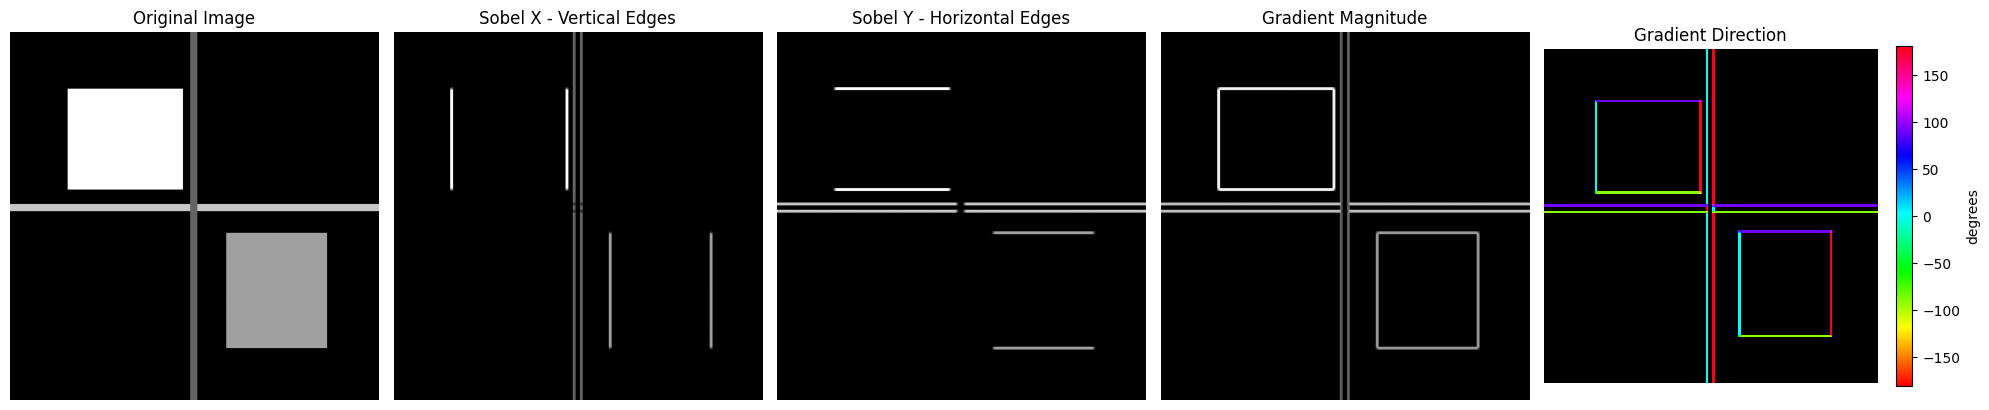

In [70]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

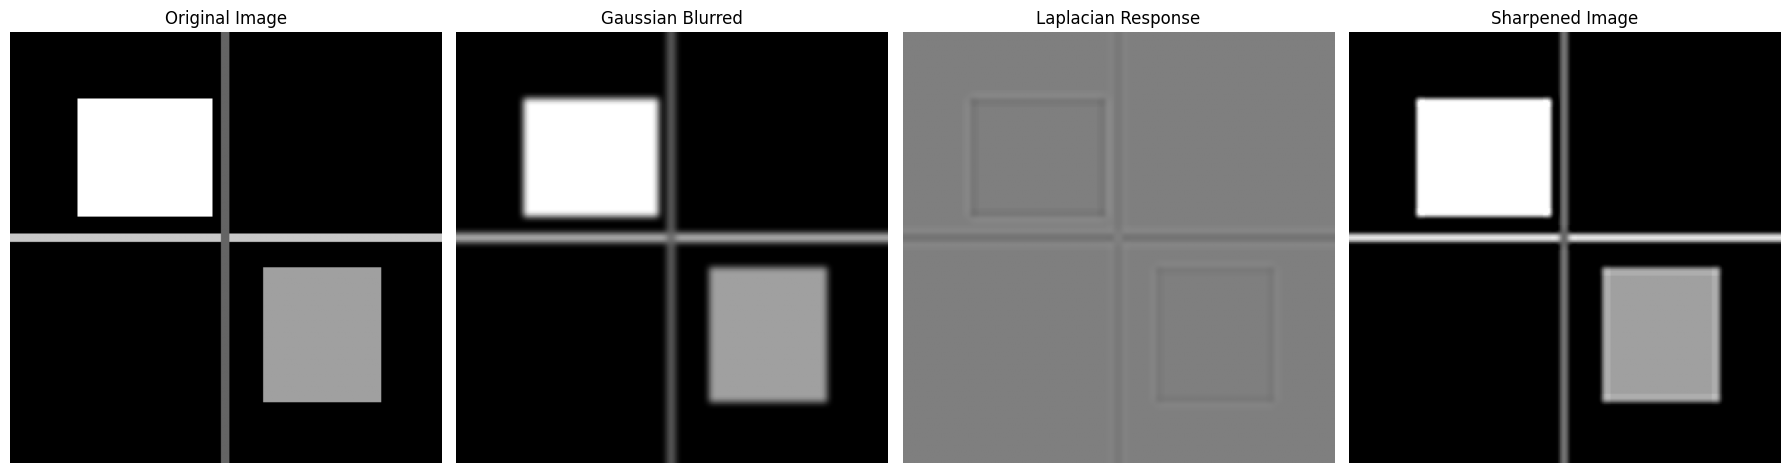

In [71]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

laplacian_display = np.clip(
    127.5 + laplacian / 2, 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

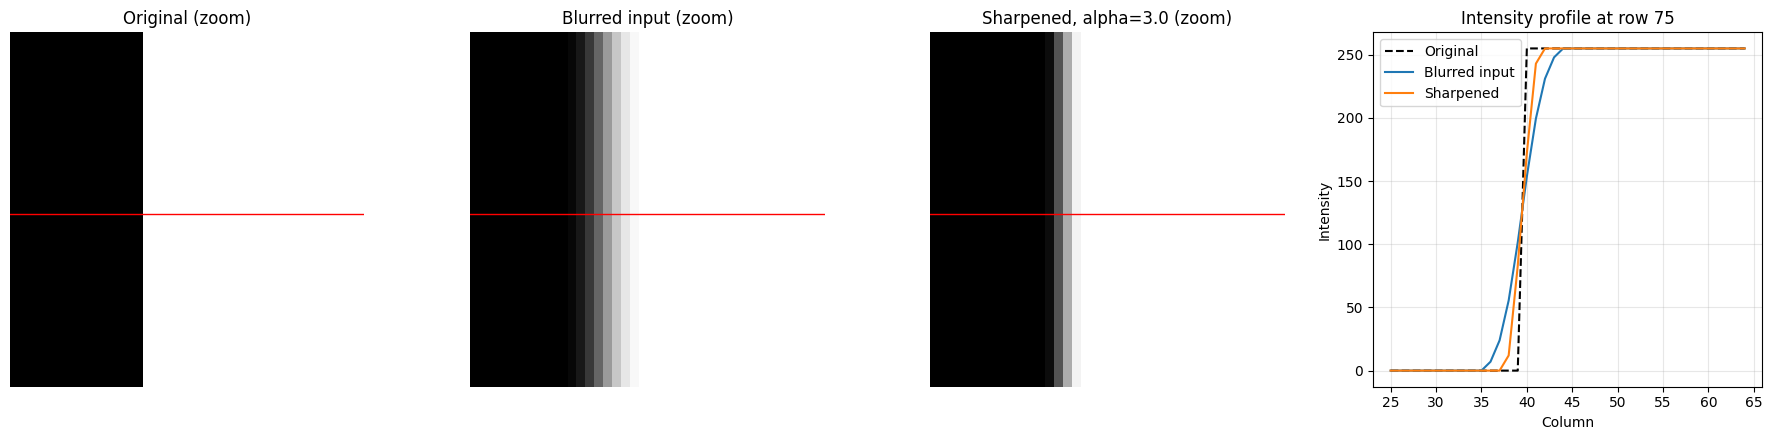

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [72]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

In [73]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


## KT3 – Ảnh thử

## KT3 – hough_accumulate, find_peaks

In [74]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path



## Vòng 2 – KT3: Bỏ phiếu Hough và tìm đỉnh

Mục tiêu của phần này là tự cài đặt hai hàm:

- `hough_accumulate()`: cho mỗi điểm cạnh bỏ phiếu vào không gian tham số \((\rho,\theta)\). Hàm hỗ trợ cả bỏ phiếu thông thường và bỏ phiếu có giới hạn theo hướng gradient.
- `find_peaks()`: làm mượt bảng tích lũy bằng hàm `convolve2d()` của nhóm, sau đó tìm các đỉnh nổi bật và loại bỏ các đỉnh lân cận trùng nhau.

Quy ước sử dụng trong bài:

\[
\rho=x\cos\theta+y\sin\theta
\]

Trong đó \(x\) là chỉ số cột, \(y\) là chỉ số hàng và \(\theta\in[0^\circ,180^\circ)\). Giá trị \(\rho\) được lượng tử hóa về số nguyên gần nhất để thuận tiện cho việc kiểm tra đáp án chuẩn.

In [75]:
# Định nghĩa hough_accumulate()
# Định nghĩa find_peaks()

import numpy as np


def hough_accumulate(
    edge_map,
    gx=None,
    gy=None,
    use_gradient=False,
    theta_step=1.0,
    rho_step=1.0,
    gradient_tolerance=10.0,
    min_gradient=1e-6,
):
    """
    Tính bảng phiếu Hough cho ảnh nhị phân cạnh.

    Quy ước:
        rho = x*cos(theta) + y*sin(theta)
        theta thuộc [0, 180) độ.

    use_gradient=False:
        Mỗi điểm cạnh bỏ phiếu cho mọi theta.

    use_gradient=True:
        Điểm có gradient đáng tin cậy chỉ bỏ phiếu gần
        hướng pháp tuyến của gradient. Điểm gradient yếu
        được bỏ phiếu đầy đủ để tránh mất đường mảnh 1 pixel.

    Trả về:
        accumulator, rhos, thetas (thetas tính bằng radian)
    """
    edge_map = np.asarray(edge_map)

    if edge_map.ndim != 2:
        raise ValueError("edge_map phải là ảnh 2D.")

    if theta_step <= 0 or rho_step <= 0:
        raise ValueError("theta_step và rho_step phải dương.")

    edges = np.isfinite(edge_map) & (edge_map > 0)
    ys, xs = np.nonzero(edges)

    height, width = edge_map.shape
    max_rho = int(np.ceil(np.hypot(width - 1, height - 1)))

    rhos = np.arange(
        -max_rho, max_rho + rho_step * 0.5, rho_step,
        dtype=np.float64
    )
    theta_degrees = np.arange(0.0, 180.0, theta_step)
    thetas = np.deg2rad(theta_degrees)

    accumulator = np.zeros(
        (len(rhos), len(thetas)), dtype=np.float64
    )

    if len(xs) == 0:
        return accumulator, rhos, thetas

    # Tính rho cho từng điểm cạnh và mọi theta.
    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)

    point_rho = (
        xs[:, None] * cos_t[None, :]
        + ys[:, None] * sin_t[None, :]
    )

    rho_indices = np.rint(
        (point_rho - rhos[0]) / rho_step
    ).astype(int)

    if not use_gradient:
        valid = (
            (rho_indices >= 0)
            & (rho_indices < len(rhos))
        )
        theta_indices = np.broadcast_to(
            np.arange(len(thetas)), rho_indices.shape
        )

        np.add.at(
            accumulator,
            (rho_indices[valid], theta_indices[valid]),
            1.0
        )

    else:
        if gx is None or gy is None:
            raise ValueError(
                "use_gradient=True cần truyền cả gx và gy."
            )

        gx = np.asarray(gx, dtype=np.float64)
        gy = np.asarray(gy, dtype=np.float64)

        if gx.shape != edge_map.shape or gy.shape != edge_map.shape:
            raise ValueError("gx, gy phải cùng kích thước với edge_map.")

        gxx = gx[ys, xs]
        gyy = gy[ys, xs]
        magnitude = np.hypot(gxx, gyy)

        # Hướng gradient là hướng pháp tuyến của đường.
        normal_degrees = np.mod(
            np.rad2deg(np.arctan2(gyy, gxx)), 180.0
        )

        half_tolerance = gradient_tolerance / 2.0

        for point_i in range(len(xs)):
            if magnitude[point_i] < min_gradient:
                # Gradient yếu: không có hướng đáng tin cậy.
                # Bỏ phiếu mọi theta để không loại mất đường mảnh.
                selected_theta = np.arange(len(thetas))
            else:
                angular_distance = np.abs(
                    (theta_degrees - normal_degrees[point_i] + 90.0)
                    % 180.0 - 90.0
                )
                selected_theta = np.flatnonzero(
                    angular_distance <= half_tolerance
                )

                # Nếu không có bin nào trong ngưỡng, lấy bin gần nhất.
                if len(selected_theta) == 0:
                    selected_theta = np.array([
                        int(np.argmin(angular_distance))
                    ])

            selected_rho = rho_indices[point_i, selected_theta]
            valid = (
                (selected_rho >= 0)
                & (selected_rho < len(rhos))
            )

            np.add.at(
                accumulator,
                (selected_rho[valid], selected_theta[valid]),
                1.0
            )

    return accumulator, rhos, thetas


def find_peaks(
    accumulator,
    rhos,
    thetas,
    num_peaks=10,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5,
):
    """
    Làm mờ bảng phiếu bằng convolve2d của nhóm,
    sau đó tìm đỉnh và loại các đỉnh quá gần nhau.

    min_distance_rho: khoảng cách tối thiểu theo đơn vị rho.
    min_distance_theta: khoảng cách tối thiểu theo số độ.
    Kết quả: danh sách (rho, theta_radian, votes).
    """
    accumulator = np.asarray(accumulator, dtype=np.float64)
    rhos = np.asarray(rhos, dtype=np.float64)
    thetas = np.asarray(thetas, dtype=np.float64)

    if accumulator.shape != (len(rhos), len(thetas)):
        raise ValueError("Kích thước accumulator không khớp rhos/thetas.")

    if num_peaks <= 0:
        return []

    work = accumulator.copy()

    if smooth:
        # Dùng hàm convolve2d do nhóm tự cài đặt.
        if "convolve2d" not in globals():
            raise NameError(
                "Chưa có convolve2d. Hãy chạy cell định nghĩa hàm "
                "convolve2d của nhóm trước."
            )

        smoothing_kernel = np.ones((3, 3), dtype=np.float64) / 9.0
        work = convolve2d(
            work, smoothing_kernel, padding="reflect"
        )

    if work.size == 0 or np.max(work) <= 0:
        return []

    # Ngưỡng áp dụng trên bảng đã làm mờ.
    candidates = np.argwhere(work >= threshold)
    candidates = sorted(
        candidates,
        key=lambda rc: work[rc[0], rc[1]],
        reverse=True
    )

    theta_step_deg = (
        np.rad2deg(thetas[1] - thetas[0])
        if len(thetas) > 1 else 1.0
    )

    selected = []

    for ri, ti in candidates:
        rho_value = rhos[ri]
        theta_value = thetas[ti]
        votes = float(work[ri, ti])

        too_close = False

        for old_rho, old_theta, _ in selected:
            rho_close = abs(rho_value - old_rho) < min_distance_rho

            theta_diff = abs(
                np.rad2deg(theta_value - old_theta)
            )
            theta_diff = min(theta_diff, 180.0 - theta_diff)

            theta_close = (
                theta_diff
                < min_distance_theta * theta_step_deg
            )

            if rho_close and theta_close:
                too_close = True
                break

        if not too_close:
            selected.append(
                (float(rho_value), float(theta_value), votes)
            )

        if len(selected) >= num_peaks:
            break

    return selected


Đã nạp ảnh: ..\images\hough_test.npy
Kích thước: (400, 400)
Kiểu dữ liệu: float64
Giá trị min/max: 0.0 255.0


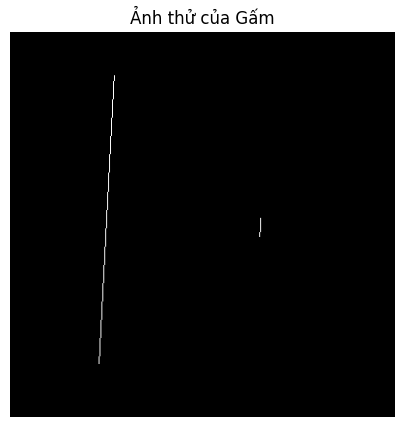

In [76]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Kiểm tra một số đường dẫn có thể có
candidates = [
    Path("../images/hough_test.npy"),
    Path("images/hough_test.npy"),
    Path("hough_test.npy"),
]

image_path = next((p for p in candidates if p.exists()), None)

if image_path is None:
    raise FileNotFoundError(
        "Không tìm thấy hough_test.npy. "
        "Hãy kiểm tra đường dẫn tới file .npy đã lưu từ notebook của Gấm."
    )

test_image = np.load(image_path)

# Chuyển về ảnh xám 2D nếu ảnh có nhiều kênh
if test_image.ndim == 3:
    test_image = test_image[..., :3].mean(axis=2)

if test_image.ndim != 2:
    raise ValueError(
        f"Ảnh phải có 2 chiều sau khi chuyển xám, "
        f"nhưng nhận được shape={test_image.shape}"
    )

test_image = test_image.astype(np.float64)

print("Đã nạp ảnh:", image_path)
print("Kích thước:", test_image.shape)
print("Kiểu dữ liệu:", test_image.dtype)
print("Giá trị min/max:", test_image.min(), test_image.max())

plt.figure(figsize=(5, 5))
plt.imshow(test_image, cmap="gray")
plt.title("Ảnh thử của Gấm")
plt.axis("off")
plt.show()


In [77]:
# Ảnh test_image đã được nạp từ hough_test.npy ở bước trước.
edge_map = (test_image > 0).astype(np.uint8)

# Tính gradient Sobel bằng convolve2d của nhóm.
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên lật kernel trước.
gx = convolve2d(
    test_image.astype(np.float64),
    np.flip(sobel_x, axis=(0, 1)),
    padding="reflect"
)
gy = convolve2d(
    test_image.astype(np.float64),
    np.flip(sobel_y, axis=(0, 1)),
    padding="reflect"
)

# 1. Không dùng gradient
acc_plain, rhos, thetas = hough_accumulate(
    edge_map,
    use_gradient=False,
    theta_step=1.0,
    rho_step=1.0
)

peaks_plain = find_peaks(
    acc_plain, rhos, thetas,
    num_peaks=10,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
)

# 2. Có dùng gradient
acc_grad, rhos_grad, thetas_grad = hough_accumulate(
    edge_map,
    gx=gx,
    gy=gy,
    use_gradient=True,
    theta_step=1.0,
    rho_step=1.0,
    gradient_tolerance=10.0
)

peaks_grad = find_peaks(
    acc_grad, rhos_grad, thetas_grad,
    num_peaks=10,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
)

def show_peaks(title, peaks):
    print("\n" + title)
    for rho, theta, votes in peaks:
        print(
            f"rho={rho:.1f}, "
            f"theta={np.rad2deg(theta):.1f} deg, "
            f"votes={votes:.2f}"
        )

show_peaks("Hough không dùng gradient", peaks_plain)
show_peaks("Hough có dùng gradient", peaks_grad)

# Kiểm tra đỉnh gần đáp án mong đợi.
def nearest_peak(peaks, rho0, theta0_deg):
    if not peaks:
        return None

    def distance(peak):
        rho, theta, _ = peak
        theta_deg = np.rad2deg(theta)
        angle_diff = abs(theta_deg - theta0_deg)
        angle_diff = min(angle_diff, 180.0 - angle_diff)
        return abs(rho - rho0), angle_diff

    return min(
        peaks,
        key=lambda p: distance(p)[0] + distance(p)[1] * 2
    )

for name, peaks in [
    ("Không gradient", peaks_plain),
    ("Có gradient", peaks_grad)
]:
    print("\nKiểm tra:", name)

    for rho0, theta0 in [(110, 3), (270, 3)]:
        peak = nearest_peak(peaks, rho0, theta0)

        if peak is None:
            print(f"FAIL: Không có đỉnh cho rho={rho0}, theta={theta0}°")
            continue

        rho_found, theta_found, votes = peak
        theta_found_deg = np.rad2deg(theta_found)

        print(
            f"Target ({rho0}, {theta0}°) -> "
            f"found ({rho_found:.1f}, {theta_found_deg:.1f}°), "
            f"votes={votes:.2f}"
        )


Hough không dùng gradient
rho=111.0, theta=4.0 deg, votes=49.00
rho=106.0, theta=1.0 deg, votes=35.78
rho=100.0, theta=0.0 deg, votes=27.00
rho=116.0, theta=5.0 deg, votes=24.89
rho=121.0, theta=6.0 deg, votes=18.44
rho=126.0, theta=7.0 deg, votes=15.22
rho=-102.0, theta=179.0 deg, votes=14.44
rho=-94.0, theta=179.0 deg, votes=14.33
rho=-89.0, theta=179.0 deg, votes=12.67
rho=131.0, theta=8.0 deg, votes=12.00

Hough có dùng gradient
rho=111.0, theta=4.0 deg, votes=43.33
rho=106.0, theta=1.0 deg, votes=32.11
rho=100.0, theta=0.0 deg, votes=24.33
rho=116.0, theta=5.0 deg, votes=22.11
rho=121.0, theta=6.0 deg, votes=16.44
rho=126.0, theta=7.0 deg, votes=13.56
rho=-102.0, theta=179.0 deg, votes=13.00
rho=-94.0, theta=179.0 deg, votes=12.89
rho=-89.0, theta=179.0 deg, votes=11.33
rho=131.0, theta=8.0 deg, votes=10.67

Kiểm tra: Không gradient
Target (110, 3°) -> found (111.0, 4.0°), votes=49.00
Target (270, 3°) -> found (131.0, 8.0°), votes=12.00

Kiểm tra: Có gradient
Target (110, 3°) -> 

In [78]:

# Kiểm tra dữ liệu đầu vào
if test_image is None:
    raise ValueError("test_image đang là None. Hãy nạp lại ảnh trước.")

if not isinstance(test_image, np.ndarray) or test_image.ndim != 2:
    raise ValueError("test_image phải là một numpy array ảnh xám 2D.")

# 1. Tạo edge map
edge_map = (test_image > 0).astype(np.uint8)

# 2. Kernel Sobel
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d của nhóm thực hiện tích chập thật,
# nên lật kernel trước để lấy gradient theo quy ước thông thường.
gx = convolve2d(
    test_image,
    np.flip(sobel_x, axis=(0, 1)),
    padding="reflect"
)

gy = convolve2d(
    test_image,
    np.flip(sobel_y, axis=(0, 1)),
    padding="reflect"
)

gradient_magnitude = np.hypot(gx, gy)

print("Số điểm cạnh:", int(edge_map.sum()))
print("Gradient magnitude lớn nhất:", gradient_magnitude.max())
print("Kích thước gx, gy:", gx.shape, gy.shape)


Số điểm cạnh: 320
Gradient magnitude lớn nhất: 1020.0
Kích thước gx, gy: (400, 400) (400, 400)


In [79]:

def inspect_target(accumulator, rhos, thetas, rho0, theta0_deg,
                   rho_window=5, theta_window_deg=3):
    theta0 = np.deg2rad(theta0_deg)

    rho_mask = np.abs(rhos - rho0) <= rho_window
    angle_distance = np.abs(
        (thetas - theta0 + np.pi / 2) % np.pi - np.pi / 2
    )
    theta_mask = angle_distance <= np.deg2rad(theta_window_deg)

    region = accumulator[np.ix_(rho_mask, theta_mask)]

    if region.size == 0:
        print("Không có ô accumulator trong vùng kiểm tra.")
        return

    local_index = np.unravel_index(np.argmax(region), region.shape)
    rho_values = rhos[rho_mask]
    theta_values = thetas[theta_mask]

    print(
        f"Target ({rho0}, {theta0_deg}°): "
        f"best nearby rho={rho_values[local_index[0]]:.1f}, "
        f"theta={np.rad2deg(theta_values[local_index[1]]):.1f}°, "
        f"votes={region[local_index]:.2f}"
    )

inspect_target(acc_plain, rhos, thetas, 110, 3)
inspect_target(acc_plain, rhos, thetas, 270, 3)
inspect_target(acc_grad, rhos_grad, thetas_grad, 110, 3)
inspect_target(acc_grad, rhos_grad, thetas_grad, 270, 3)


Target (110, 3°): best nearby rho=110.0, theta=3.0°, votes=300.00
Target (270, 3°): best nearby rho=270.0, theta=3.0°, votes=20.00
Target (110, 3°): best nearby rho=110.0, theta=3.0°, votes=266.00
Target (270, 3°): best nearby rho=270.0, theta=3.0°, votes=16.00


Đọc ảnh thử thành công: (400, 400) uint8


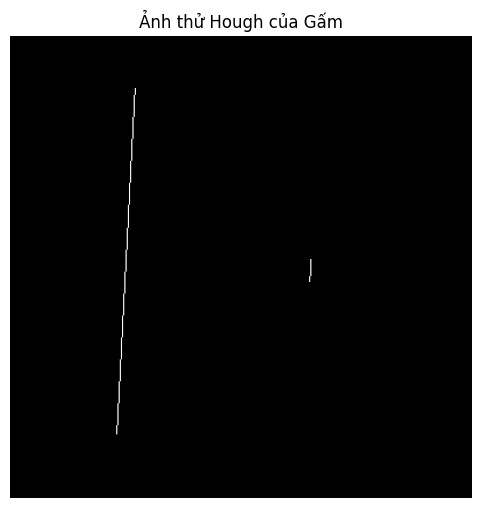

In [80]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

current = Path.cwd().resolve()
project_root = current.parent if current.name == "lam_viec" else current
images_dir = project_root / "images"

npy_path = images_dir / "hough_test.npy"

if not npy_path.is_file():
    raise FileNotFoundError(
        f"Chưa có {npy_path}. Hãy chạy cell lưu .npy trong gam.ipynb trước."
    )

test_image = np.load(npy_path, allow_pickle=False)

if test_image.ndim != 2 or test_image.shape != (400, 400):
    raise ValueError(f"Ảnh thử không đúng định dạng: {test_image.shape}")

test_image = test_image.astype(np.uint8, copy=False)

print("Đọc ảnh thử thành công:", test_image.shape, test_image.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(test_image, cmap="gray", vmin=0, vmax=255)
plt.title("Ảnh thử Hough của Gấm")
plt.axis("off")
plt.show()


In [81]:
import os
import cv2
from pathlib import Path

p = Path(r"D:\GTVT-UTH\HKI 2026-2027\Xử lý ảnh thị giác máy tính\xla-121036\images\baboon.jpg")

print("Python can read:", os.access(p, os.R_OK))
print("File bytes:", p.stat().st_size if p.exists() else "missing")

with open(p, "rb") as f:
    raw = f.read()

print("Python read bytes:", len(raw))
print("First 16 bytes:", raw[:16])

# Thử giải mã chính các byte Python vừa đọc
decoded = cv2.imdecode(
    np.frombuffer(raw, dtype=np.uint8),
    cv2.IMREAD_GRAYSCALE
)
print("OpenCV imdecode file bytes:", decoded is not None)

Python can read: True
File bytes: 179920
Python read bytes: 179920
First 16 bytes: b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x00'
OpenCV imdecode file bytes: True


###  Trực quan hóa bảng phiếu Hough

Bảng phiếu Hough biểu diễn số điểm cạnh ủng hộ từng cặp tham số \((\rho,\theta)\). Trục ngang biểu diễn góc \(\theta\) trong khoảng \([0^\circ,180^\circ)\), trục dọc biểu diễn khoảng cách có dấu \(\rho\). Các điểm cạnh cùng thuộc một đường thẳng sẽ tích lũy phiếu tại những vị trí gần nhau trong không gian Hough, tạo thành các đỉnh nổi bật.

Ta trực quan hóa bảng phiếu trước và sau khi áp dụng bỏ phiếu theo hướng gradient để quan sát sự khác biệt.

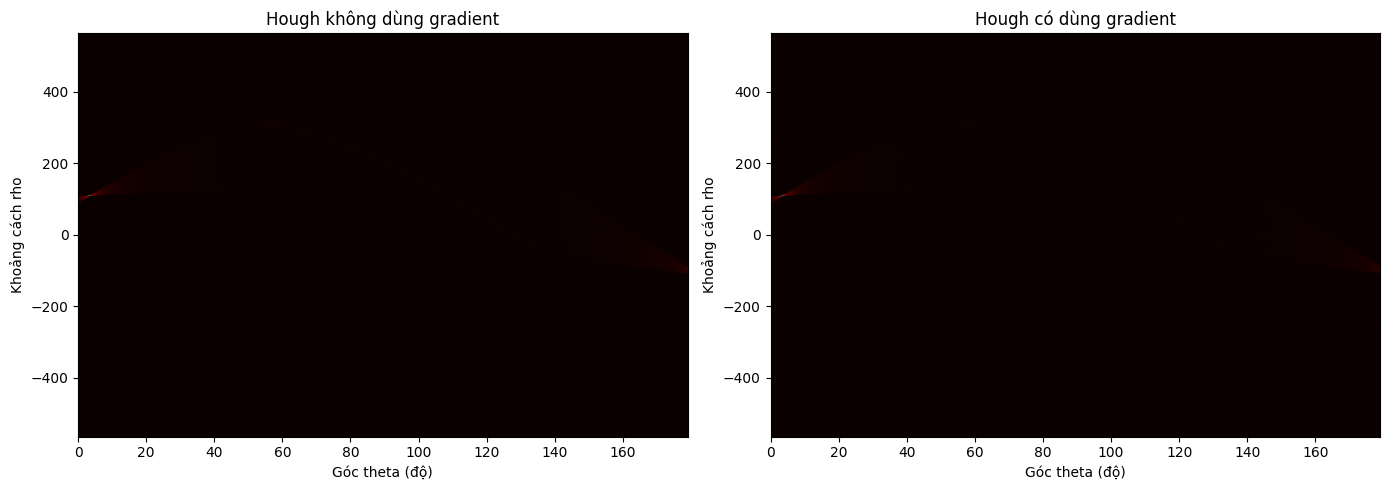

In [82]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, accumulator, title in [
    (axes[0], acc_plain, "Hough không dùng gradient"),
    (axes[1], acc_grad, "Hough có dùng gradient"),
]:
    ax.imshow(
        accumulator,
        aspect="auto",
        origin="lower",
        extent=[
            np.rad2deg(thetas[0]),
            np.rad2deg(thetas[-1]),
            rhos[0],
            rhos[-1],
        ],
        cmap="hot",
    )
    ax.set_xlabel("Góc theta (độ)")
    ax.set_ylabel("Khoảng cách rho")
    ax.set_title(title)

plt.tight_layout()
plt.show()


In [83]:

def target_peak_check(
    accumulator, rhos, thetas,
    rho0, theta0_deg,
    rho_tolerance=5,
    theta_tolerance_deg=3
):
    theta_deg = np.rad2deg(thetas)

    rho_mask = np.abs(rhos - rho0) <= rho_tolerance
    theta_distance = np.abs(
        (theta_deg - theta0_deg + 90) % 180 - 90
    )
    theta_mask = theta_distance <= theta_tolerance_deg

    if not np.any(rho_mask) or not np.any(theta_mask):
        return None

    region = accumulator[np.ix_(rho_mask, theta_mask)]
    if region.size == 0:
        return None

    local_r, local_t = np.unravel_index(
        np.argmax(region), region.shape
    )

    rho_candidates = rhos[rho_mask]
    theta_candidates = thetas[theta_mask]

    return (
        float(rho_candidates[local_r]),
        float(theta_candidates[local_t]),
        float(region[local_r, local_t]),
    )


targets = [
    (110, 3, "Đường dài"),
    (270, 3, "Đường ngắn"),
]

for mode_name, accumulator, rho_values, theta_values in [
    ("Không gradient", acc_plain, rhos, thetas),
    ("Có gradient", acc_grad, rhos_grad, thetas_grad),
]:
    print(f"\n--- {mode_name} ---")

    for rho0, theta0, label in targets:
        result = target_peak_check(
            accumulator, rho_values, theta_values,
            rho0, theta0
        )

        if result is None:
            print(f"FAIL | {label}: không có vùng kiểm tra hợp lệ")
            continue

        rho_found, theta_found, votes = result
        theta_found_deg = np.rad2deg(theta_found)

        rho_error = abs(rho_found - rho0)
        theta_error = abs(
            (theta_found_deg - theta0 + 90) % 180 - 90
        )

        passed = rho_error <= 5 and theta_error <= 3

        print(
            f"{'PASS' if passed else 'CHECK'} | {label} | "
            f"rho={rho_found:.1f} (sai số {rho_error:.1f}) | "
            f"theta={theta_found_deg:.1f}° "
            f"(sai số {theta_error:.1f}°) | "
            f"phiếu={votes:.2f}"
        )



--- Không gradient ---
PASS | Đường dài | rho=110.0 (sai số 0.0) | theta=3.0° (sai số 0.0°) | phiếu=300.00
PASS | Đường ngắn | rho=270.0 (sai số 0.0) | theta=3.0° (sai số 0.0°) | phiếu=20.00

--- Có gradient ---
PASS | Đường dài | rho=110.0 (sai số 0.0) | theta=3.0° (sai số 0.0°) | phiếu=266.00
PASS | Đường ngắn | rho=270.0 (sai số 0.0) | theta=3.0° (sai số 0.0°) | phiếu=16.00


In [84]:

import time

def timed_hough(edge_map, gx=None, gy=None, use_gradient=False):
    start = time.perf_counter()

    accumulator, rhos_out, thetas_out = hough_accumulate(
        edge_map,
        gx=gx,
        gy=gy,
        use_gradient=use_gradient,
        theta_step=1.0,
        rho_step=1.0,
    )

    elapsed = time.perf_counter() - start
    return accumulator, rhos_out, thetas_out, elapsed


_, _, _, time_plain = timed_hough(
    edge_map, use_gradient=False
)

_, _, _, time_grad = timed_hough(
    edge_map, gx=gx, gy=gy, use_gradient=True
)

print(f"Thời gian không gradient: {time_plain:.4f} giây")
print(f"Thời gian có gradient:    {time_grad:.4f} giây")

if time_plain > 0:
    print(f"Tỉ lệ thời gian: {time_grad / time_plain:.2f}x")


Thời gian không gradient: 0.0067 giây
Thời gian có gradient:    0.0116 giây
Tỉ lệ thời gian: 1.72x


###  Phân tích kết quả

**Nguyên lý bỏ phiếu Hough.** Một điểm cạnh \((x,y)\) có thể nằm trên nhiều đường thẳng khác nhau. Với mỗi góc \(\theta\), điểm đó xác định một khoảng cách \(\rho=x\cos\theta+y\sin\theta\), do đó bỏ phiếu cho một ô tương ứng trong bảng phiếu. Khi nhiều điểm cạnh cùng nằm trên một đường thẳng, các phiếu tập trung gần cùng một cặp \((\rho,\theta)\), tạo thành đỉnh.

**Vai trò của `find_peaks`.** Làm mờ bảng phiếu giúp giảm dao động giữa các ô lân cận. Bước loại bỏ đỉnh gần nhau giúp tránh trả về nhiều đỉnh gần như mô tả cùng một đường thẳng. Nếu bước loại bỏ lân cận không được áp dụng đúng, danh sách kết quả có thể chứa nhiều góc gần nhau của cùng một đường và bỏ sót đường ngắn.

**So sánh bỏ phiếu theo gradient.** Hướng gradient của ảnh xấp xỉ hướng pháp tuyến của cạnh. Khi hướng gradient đáng tin cậy, chỉ bỏ phiếu cho các góc gần hướng pháp tuyến có thể giảm số phép bỏ phiếu. Tuy nhiên, ở các đường mảnh một pixel, gradient tại chính điểm cạnh có thể yếu hoặc không ổn định; khi đó việc giới hạn góc quá chặt có thể làm giảm số phiếu và khiến đường khó được phát hiện.

**Giới hạn của thí nghiệm.** Hai đoạn thẳng thử có độ dài khác nhau nên đường dài thường tích lũy nhiều phiếu hơn đường ngắn. Vì vậy, cần kiểm tra cả vùng lân cận của hai đáp án đã biết thay vì chỉ xem danh sách các đỉnh mạnh nhất.